In [ ]:
%cd /content/drive/MyDrive/Colab Notebooks/Domain Adaptation

/content/drive/MyDrive/Colab Notebooks/Domain Adaptation


In [ ]:
!pip install -q scikit-learn tqdm


In [ ]:
SRC = "/content/drive/MyDrive/Colab Notebooks/Domain Adaptation/ISIC2019_merged"
TGT_TRAIN = "/content/drive/MyDrive/Colab Notebooks/Domain Adaptation/fitz_unlabeled/dummy"
TGT_EVAL = "/content/drive/MyDrive/Colab Notebooks/Domain Adaptation/fitz_selected"
SAVE = "/content/drive/MyDrive/MDD_Project2/checkpoints"


In [ ]:
!python mdd_mobilenetv2_ep2.py \
  --src_root "$SRC" \
  --tgt_train_root "$TGT_TRAIN" \
  --tgt_eval_root "$TGT_EVAL" \
  --save_dir "$SAVE"


[INFO] Unlabeled target images: 2059
Source classes: {'ak': 0, 'bcc': 1, 'bkl': 2, 'df': 3, 'mel': 4, 'nv': 5, 'scc': 6}
Target classes: {'ak': 0, 'bcc': 1, 'bkl': 2, 'df': 3, 'mel': 4, 'nv': 5, 'scc': 6}
Epoch [1/30] | Loss: 107.2987 | Target Acc: 0.1880 | F1: 0.1449
Epoch [2/30] | Loss: 82.8390 | Target Acc: 0.2113 | F1: 0.1704
Epoch [3/30] | Loss: 81.4395 | Target Acc: 0.2108 | F1: 0.1757
Epoch [4/30] | Loss: 82.1989 | Target Acc: 0.2132 | F1: 0.1862
Epoch [5/30] | Loss: 73.5203 | Target Acc: 0.2122 | F1: 0.2044
Epoch [6/30] | Loss: 66.3079 | Target Acc: 0.2424 | F1: 0.2027
Epoch [7/30] | Loss: 64.9242 | Target Acc: 0.2419 | F1: 0.2154
Epoch [8/30] | Loss: 66.5872 | Target Acc: 0.2302 | F1: 0.1833
Epoch [9/30] | Loss: 56.6868 | Target Acc: 0.1986 | F1: 0.1771
Epoch [10/30] | Loss: 56.4638 | Target Acc: 0.2705 | F1: 0.2389
Epoch [11/30] | Loss: 54.7621 | Target Acc: 0.1841 | F1: 0.1737
Epoch [12/30] | Loss: 56.4137 | Target Acc: 0.2356 | F1: 0.1979
Epoch [13/30] | Loss: 48.4341 | Tar

In [ ]:
import torch
from mdd_mobilenetv2_ep2 import MDDMobileNet

device = "cuda" if torch.cuda.is_available() else "cpu"

model = MDDMobileNet(num_classes=7).to(device)

ckpt_path = "/content/drive/MyDrive/MDD_Project2/checkpoints/mdd_best.pth"
# or: mdd_epoch_30.pth

model.load_state_dict(torch.load(ckpt_path, map_location=device))
model.eval()

print("✅ Model loaded:", ckpt_path)


✅ Model loaded: /content/drive/MyDrive/MDD_Project2/checkpoints/mdd_best.pth


In [ ]:
from torchvision import transforms
from torchvision.datasets import ImageFolder
from torch.utils.data import DataLoader

# Use the SAME transforms as training evaluation
transform_test = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor()
])

TGT_EVAL_ROOT = "/content/drive/MyDrive/Colab Notebooks/Domain Adaptation/fitz_selected"

target_test_dataset = ImageFolder(
    root=TGT_EVAL_ROOT,
    transform=transform_test
)

target_test_loader = DataLoader(
    target_test_dataset,
    batch_size=32,
    shuffle=False
)

class_names = target_test_dataset.classes
print("Classes:", class_names)


Classes: ['ak', 'bcc', 'bkl', 'df', 'mel', 'nv', 'scc']


In [ ]:
import torch
import numpy as np
from tqdm import tqdm

device = "cuda" if torch.cuda.is_available() else "cpu"

all_preds = []
all_labels = []

model.eval()
with torch.no_grad():
    for x, y in tqdm(target_test_loader):
        x = x.to(device)
        y = y.to(device)

        logits, _ = model(x)
        preds = logits.argmax(dim=1)

        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(y.cpu().numpy())

all_preds = np.array(all_preds)
all_labels = np.array(all_labels)

print("✅ Evaluation samples:", len(all_labels))


100%|██████████| 65/65 [00:18<00:00,  3.43it/s]

✅ Evaluation samples: 2059


In [ ]:
from sklearn.metrics import accuracy_score, precision_recall_fscore_support

acc = accuracy_score(all_labels, all_preds)
p, r, f1, _ = precision_recall_fscore_support(
    all_labels,
    all_preds,
    average="macro",
    zero_division=0
)

print(f"Accuracy : {acc:.4f}")
print(f"Precision: {p:.4f}")
print(f"Recall   : {r:.4f}")
print(f"F1-score : {f1:.4f}")


Accuracy : 0.2705
Precision: 0.3039
Recall   : 0.2759
F1-score : 0.2389


In [ ]:
from sklearn.metrics import classification_report

print(classification_report(
    all_labels,
    all_preds,
    target_names=class_names,
    digits=4,
    zero_division=0
))


              precision    recall  f1-score   support

          ak     0.3088    0.1200    0.1728       175
         bcc     0.4413    0.2180    0.2918       500
         bkl     0.0605    0.3623    0.1037        69
          df     0.2708    0.1646    0.2047        79
         mel     0.3269    0.3700    0.3471       500
          nv     0.2287    0.5466    0.3225       236
         scc     0.4902    0.1500    0.2297       500

    accuracy                         0.2705      2059
   macro avg     0.3039    0.2759    0.2389      2059
weighted avg     0.3705    0.2705    0.2739      2059



In [ ]:
from sklearn.metrics import confusion_matrix
import pandas as pd

cm = confusion_matrix(all_labels, all_preds)

cm_df = pd.DataFrame(
    cm,
    index=class_names,
    columns=class_names
)

cm_df


,ak,bcc,bkl,df,mel,nv,scc
ak,21,11,53,0,59,27,4
bcc,20,109,107,4,120,98,42
bkl,1,1,25,0,16,26,0
df,2,9,5,13,4,42,4
mel,8,39,66,9,185,171,22
nv,5,9,24,14,49,129,6
scc,11,69,133,8,133,71,75


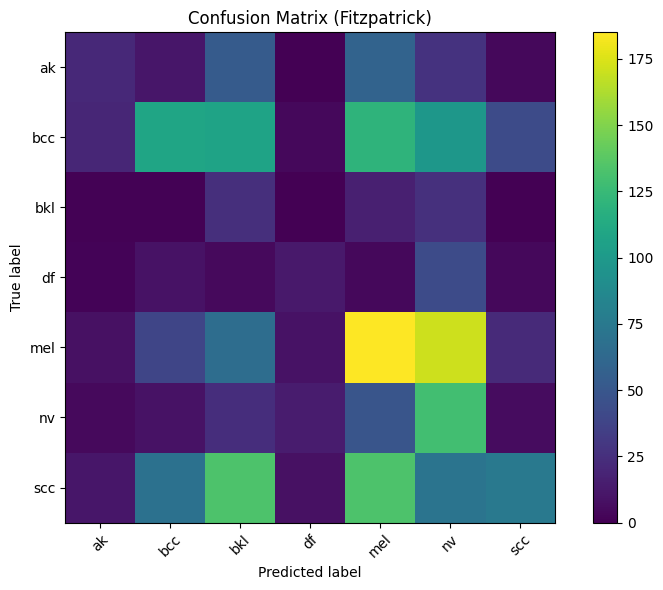

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))
plt.imshow(cm, interpolation="nearest")
plt.title("Confusion Matrix (Fitzpatrick)")
plt.colorbar()

plt.xticks(range(len(class_names)), class_names, rotation=45)
plt.yticks(range(len(class_names)), class_names)

plt.xlabel("Predicted label")
plt.ylabel("True label")
plt.tight_layout()
plt.show()


In [ ]:
import torch
import matplotlib.pyplot as plt
import numpy as np
from torchvision import transforms
from collections import defaultdict


In [ ]:
@torch.no_grad()
def collect_predictions(model, loader, device):
    model.eval()

    records = []  # (image, true_label, pred_label, confidence)

    for images, labels in loader:
        images = images.to(device)
        logits, _ = model(images)
        probs = torch.softmax(logits, dim=1)

        confs, preds = torch.max(probs, dim=1)

        for i in range(images.size(0)):
            records.append((
                images[i].cpu(),
                labels[i].item(),
                preds[i].item(),
                confs[i].item()
            ))
    return records


In [ ]:
def group_by_class(records, class_names):
    grouped = defaultdict(list)
    for img, y_true, y_pred, conf in records:
        grouped[class_names[y_true]].append((img, y_pred, conf))
    return grouped


In [ ]:
def show_samples_per_class(grouped, class_names, n=5):
    num_classes = len(class_names)
    fig, axes = plt.subplots(num_classes, n, figsize=(n*3, num_classes*3))

    for row, cls in enumerate(class_names):
        samples = grouped.get(cls, [])
        if len(samples) == 0:
            continue

        for col in range(n):
            img, pred, conf = samples[col % len(samples)]

            img = img.permute(1, 2, 0)
            img = (img - img.min()) / (img.max() - img.min())

            axes[row, col].imshow(img)
            axes[row, col].axis("off")
            axes[row, col].set_title(
                f"GT: {cls}\nPred: {class_names[pred]}\nConf: {conf:.2f}",
                fontsize=9
            )
    plt.tight_layout()
    plt.show()


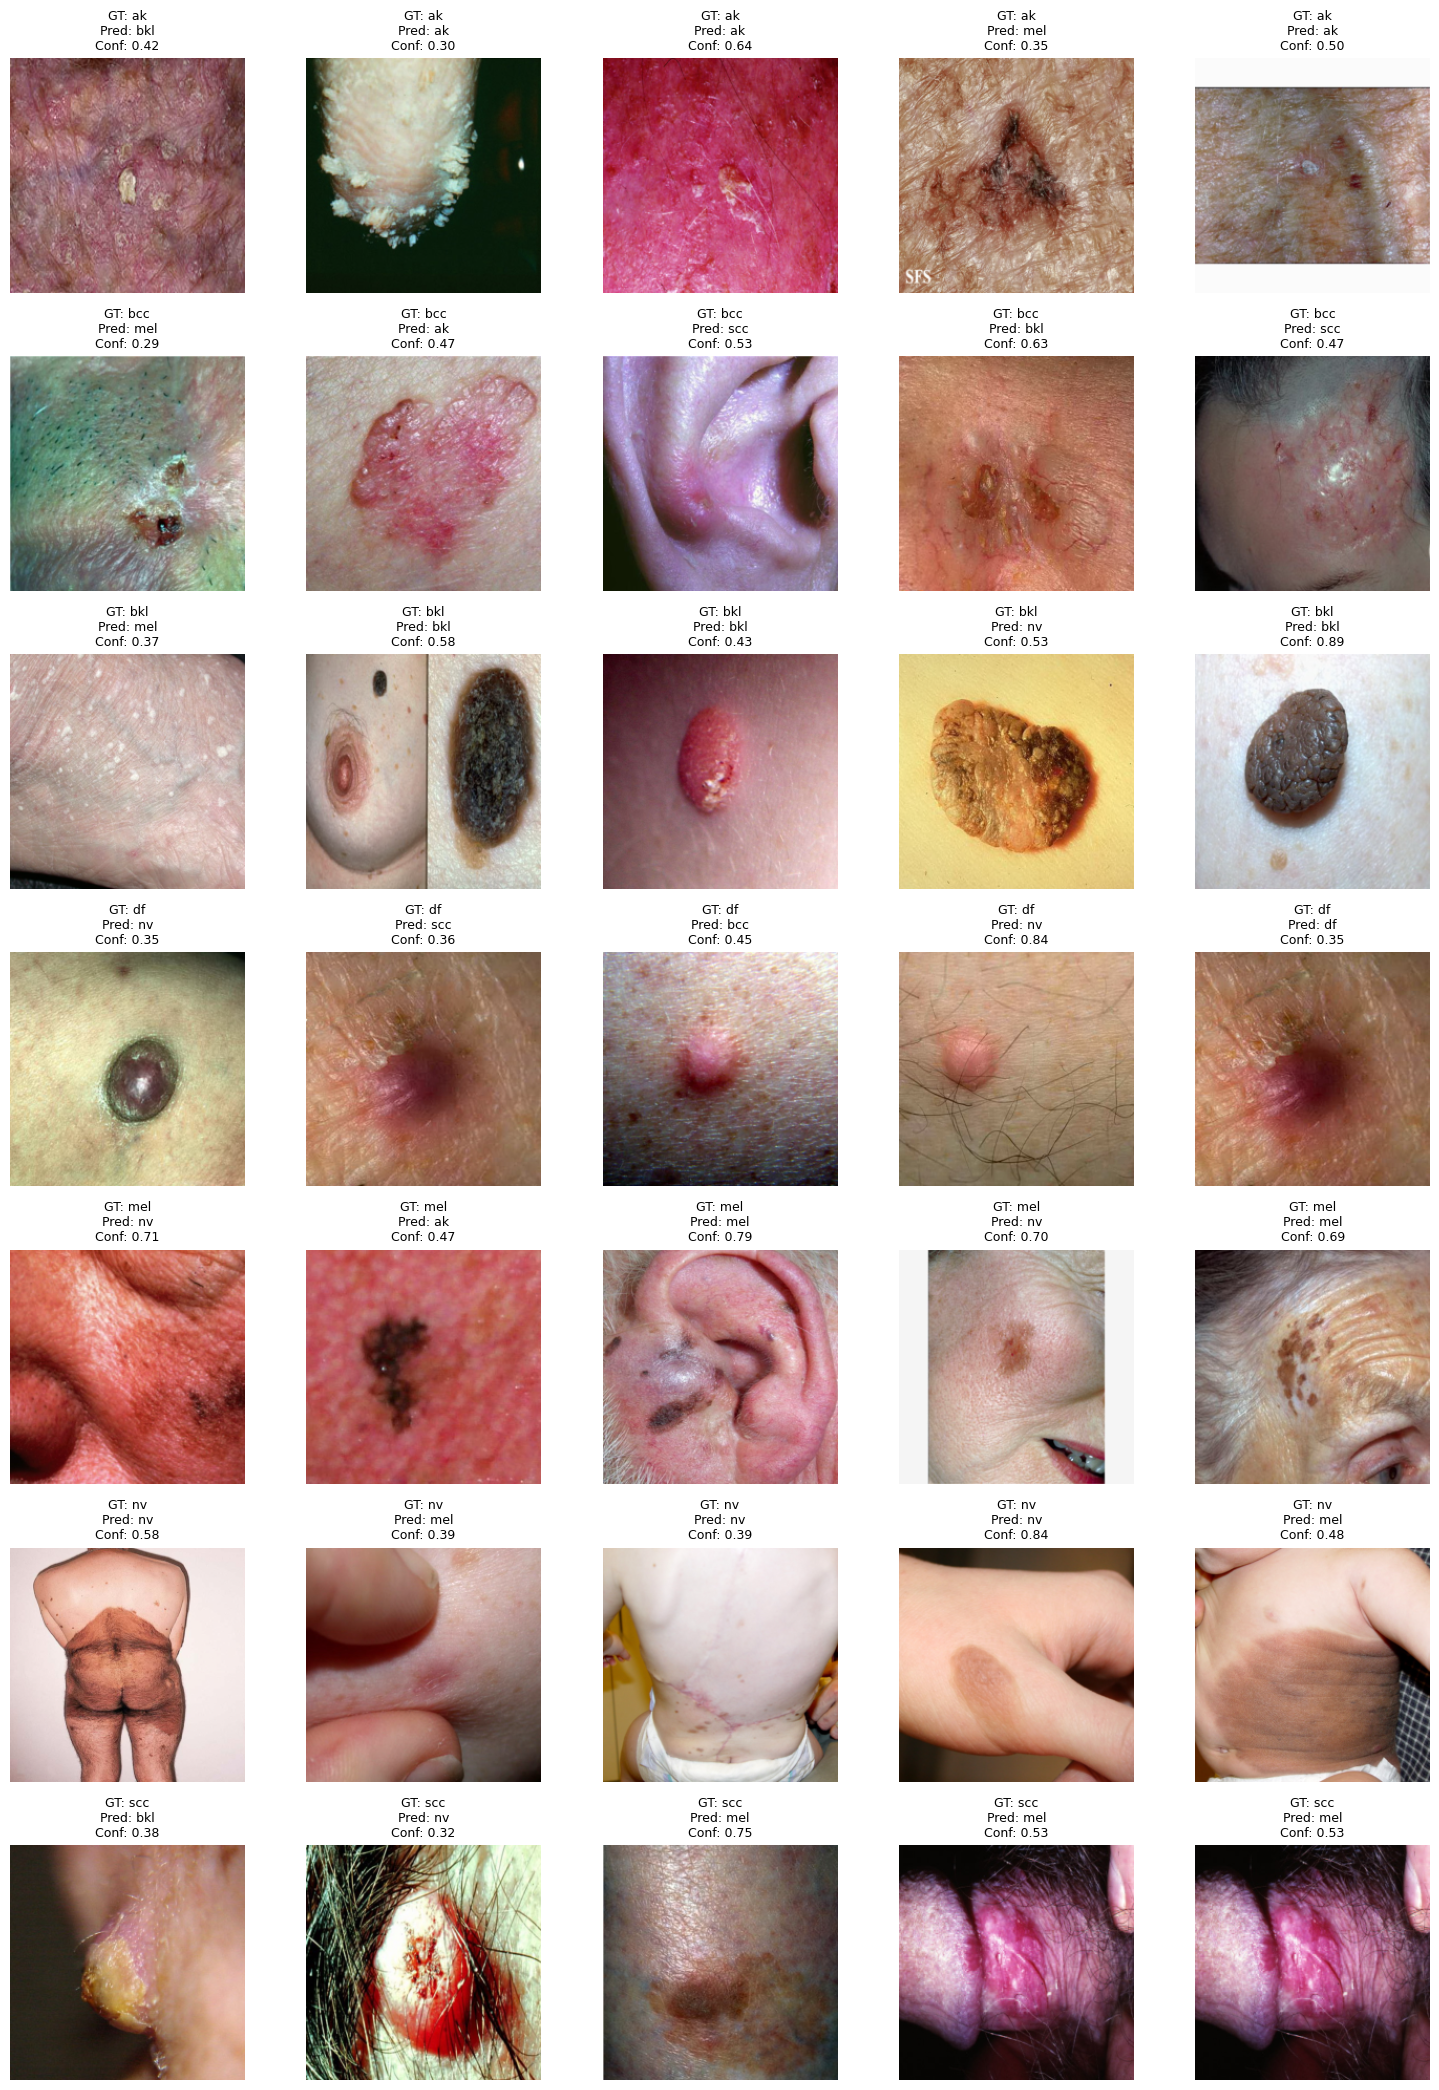

In [ ]:

lass_names = ['ak', 'bcc', 'bkl', 'df', 'mel', 'nv', 'scc']

records = collect_predictions(model, target_test_loader, device)
grouped = group_by_class(records, class_names)

show_samples_per_class(grouped, class_names, n=5)
